In [1]:
import ee
ee.Initialize(project="tree-fire-510209")

florida_bbox = ee.Geometry.Rectangle([-85.6, 30.0, -84.9, 30.6])

agb = ee.ImageCollection("ESA/CCI/Above_Ground_Biomass/V6_0")

for year in [2017, 2019]:
    img = agb.filterDate(f"{year}-01-01", f"{year}-12-31").first()
    url = img.getDownloadURL({"scale": 100, "region": florida_bbox, "format": "GEO_TIFF"})
    print(year, url)


2017 https://earthengine.googleapis.com/v1/projects/tree-fire-510209/thumbnails/02cfefb5a997c7c15e06f278fd92f750-c592aef6f578fe6efe497f324d589106:getPixels
2019 https://earthengine.googleapis.com/v1/projects/tree-fire-510209/thumbnails/b288150c79cd796b921518f7c1f5192e-2269ee8e7b2d37a4c8572a913c7aea07:getPixels


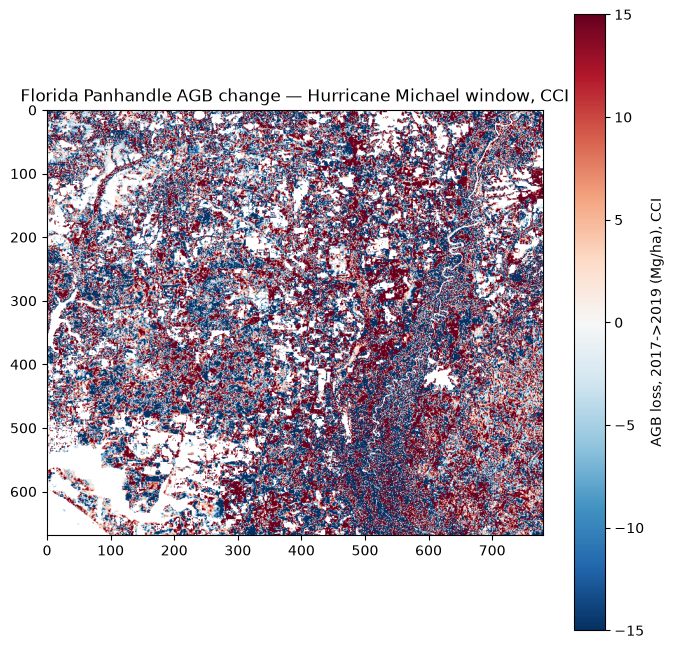

In [2]:
import rasterio
import numpy as np
import matplotlib.pyplot as plt

with rasterio.open("../data/raw/agb/agb_florida_2017.tif") as src:
    agb_2017 = src.read(1, masked=True).astype("float32").filled(np.nan)
with rasterio.open("../data/raw/agb/agb_florida_2019.tif") as src:
    agb_2019 = src.read(1, masked=True).astype("float32").filled(np.nan)

loss_florida = agb_2017 - agb_2019

fig, ax = plt.subplots(figsize=(8, 8))
im = ax.imshow(loss_florida, cmap="RdBu_r", vmin=-15, vmax=15)
plt.colorbar(im, label="AGB loss, 2017->2019 (Mg/ha), CCI")
plt.title("Florida Panhandle AGB change — Hurricane Michael window, CCI")
plt.savefig("../data/raw/cci_loss_florida.png", dpi=150)
plt.show()


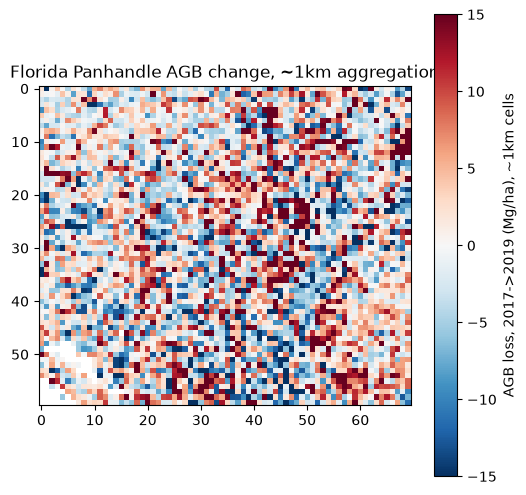

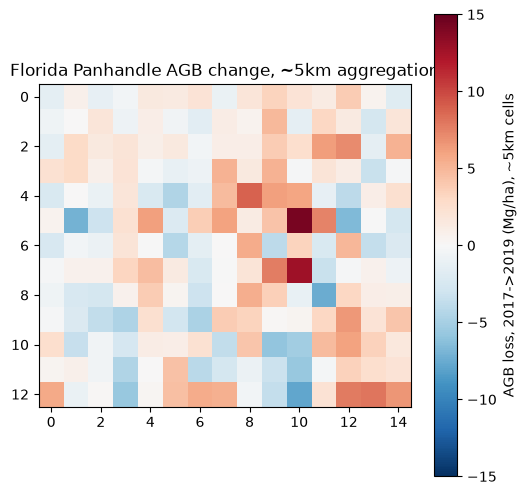

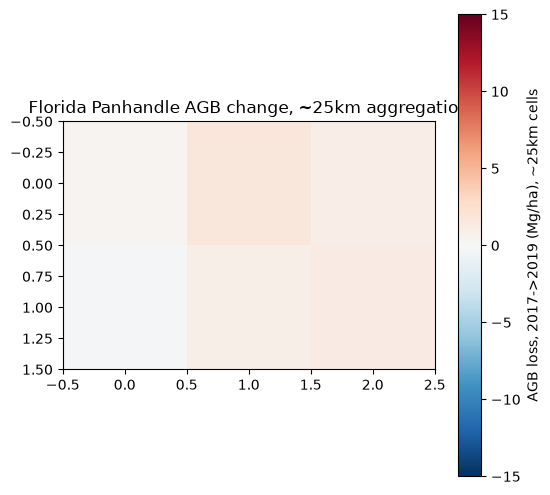

In [4]:
import sys
sys.path.insert(0, "../src")
from grids import reproject_to_grid
from rasterio.transform import from_origin
from rasterio.warp import Resampling

def aggregate(path, cell_size_deg):
    with rasterio.open(path) as src:
        arr = src.read(1)
        src_transform, src_crs = src.transform, src.crs
        bounds = src.bounds
        nodata = src.nodata

    width = int((bounds.right - bounds.left) / cell_size_deg)
    height = int((bounds.top - bounds.bottom) / cell_size_deg)
    dst_transform = from_origin(bounds.left, bounds.top, cell_size_deg, cell_size_deg)

    return reproject_to_grid(
        arr, src_transform, src_crs,
        dst_shape=(height, width), dst_transform=dst_transform, dst_crs=src_crs,
        resampling=Resampling.average, src_nodata=nodata,
    )

cell_sizes_deg = {"~1km": 0.01, "~5km": 0.045, "~25km": 0.225}

for label, cell_size in cell_sizes_deg.items():
    agb_2017_agg = aggregate("../data/raw/agb/agb_florida_2017.tif", cell_size)
    agb_2019_agg = aggregate("../data/raw/agb/agb_florida_2019.tif", cell_size)
    loss_agg = agb_2017_agg - agb_2019_agg

    fig, ax = plt.subplots(figsize=(6, 6))
    im = ax.imshow(loss_agg, cmap="RdBu_r", vmin=-15, vmax=15)
    plt.colorbar(im, label=f"AGB loss, 2017->2019 (Mg/ha), {label} cells")
    plt.title(f"Florida Panhandle AGB change, {label} aggregation")
    plt.savefig(f"../data/raw/cci_loss_florida_{label.replace('~','').replace(' ','_')}.png", dpi=150)
    plt.show()


In [5]:
florida_bbox_v2 = ee.Geometry.Rectangle([-85.7, 29.6, -84.6, 30.6])

for year in [2017, 2019]:
    img = agb.filterDate(f"{year}-01-01", f"{year}-12-31").first()
    url = img.getDownloadURL({"scale": 100, "region": florida_bbox_v2, "format": "GEO_TIFF"})
    print(year, url)


2017 https://earthengine.googleapis.com/v1/projects/tree-fire-510209/thumbnails/e21ab4af0590945cc9c916adcc0a6af5-7786b1b9161d9c5bacd66a1a713797c8:getPixels
2019 https://earthengine.googleapis.com/v1/projects/tree-fire-510209/thumbnails/d3c7c04b16e9e15ffc5500887be2507a-8050e9ba00105de53d073fa2fe66e237:getPixels


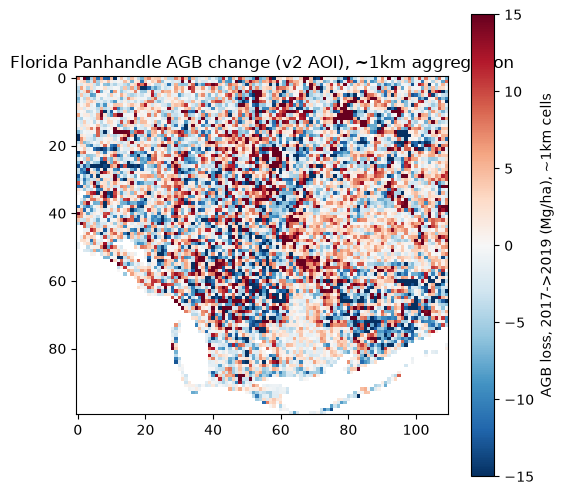

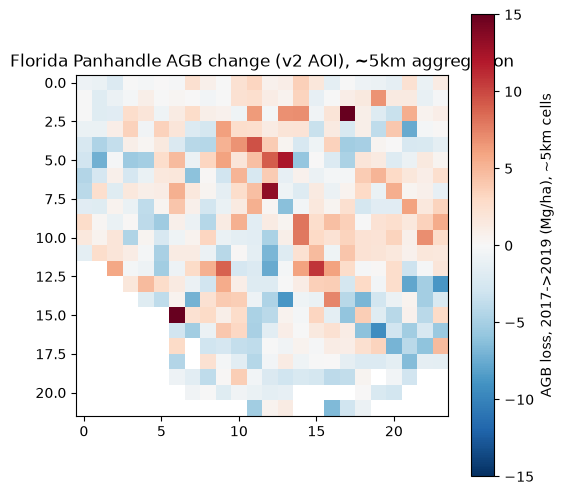

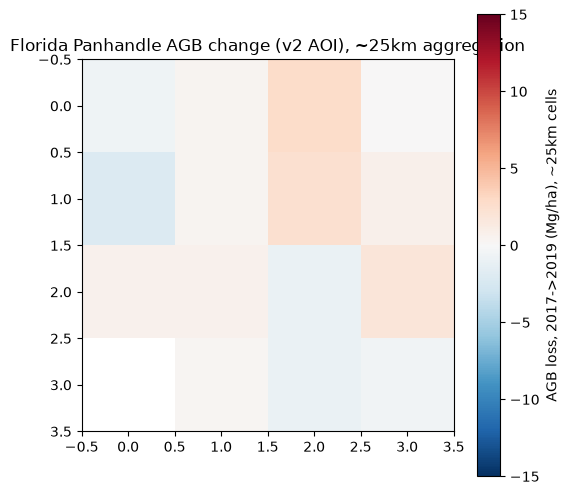

In [6]:
cell_sizes_deg = {"~1km": 0.01, "~5km": 0.045, "~25km": 0.225}

for label, cell_size in cell_sizes_deg.items():
    agb_2017_agg = aggregate("../data/raw/agb/agb_florida_v2_2017.tif", cell_size)
    agb_2019_agg = aggregate("../data/raw/agb/agb_florida_v2_2019.tif", cell_size)
    loss_agg = agb_2017_agg - agb_2019_agg

    fig, ax = plt.subplots(figsize=(6, 6))
    im = ax.imshow(loss_agg, cmap="RdBu_r", vmin=-15, vmax=15)
    plt.colorbar(im, label=f"AGB loss, 2017->2019 (Mg/ha), {label} cells")
    plt.title(f"Florida Panhandle AGB change (v2 AOI), {label} aggregation")
    plt.savefig(f"../data/raw/cci_loss_florida_v2_{label.replace('~','').replace(' ','_')}.png", dpi=150)
    plt.show()


In [7]:
hansen = ee.Image("UMD/hansen/global_forest_change_2023_v1_11")
lossyear = hansen.select("lossyear")

url_lossyear = lossyear.getDownloadURL({"scale": 100, "region": florida_bbox_v2, "format": "GEO_TIFF"})
print(url_lossyear)


/home/jupyter/fire-impact-curves/.venv/lib/python3.12/site-packages/ee/deprecation.py:215: DeprecationWarning: 

Attention required for UMD/hansen/global_forest_change_2023_v1_11! You are using a deprecated asset.
To make sure your code keeps working, please update it.
This dataset has been superseded by UMD/hansen/global_forest_change_2025_v1_13

Learn more: https://developers.google.com/earth-engine/datasets/catalog/UMD_hansen_global_forest_change_2023_v1_11

  warnings.warn(warning, category=DeprecationWarning)


https://earthengine.googleapis.com/v1/projects/tree-fire-510209/thumbnails/381cb662e99af2fbd52cf26322041c13-fccd86b3e7f14e57e05dec5b7518047b:getPixels


fraction of bbox with Hansen-detected 2018 canopy loss: 0.040838270792187846


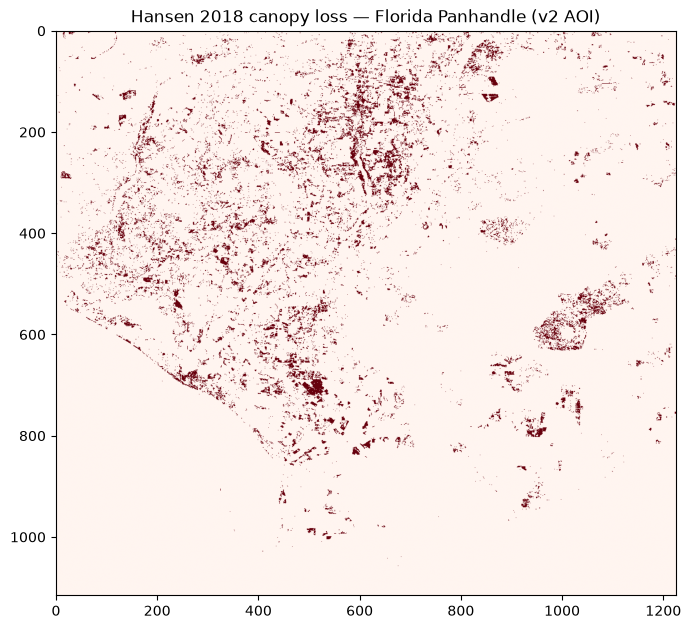

In [8]:
with rasterio.open("../data/raw/hansen_lossyear_florida_v2.tif") as src:
    lossyear = src.read(1)

loss_2018 = lossyear == 18
print("fraction of bbox with Hansen-detected 2018 canopy loss:", loss_2018.mean())

fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(loss_2018, cmap="Reds")
plt.title("Hansen 2018 canopy loss — Florida Panhandle (v2 AOI)")
plt.savefig("../data/raw/hansen_2018_loss_florida.png", dpi=150)
plt.show()


In [9]:
for year, code in [(2016, 16), (2017, 17), (2019, 19)]:
    loss_year = lossyear == code
    print(f"fraction of bbox with Hansen-detected {year} canopy loss:", loss_year.mean())


fraction of bbox with Hansen-detected 2016 canopy loss: 0.02122302684514666
fraction of bbox with Hansen-detected 2017 canopy loss: 0.018478531197425208
fraction of bbox with Hansen-detected 2019 canopy loss: 0.05025235900811938
